In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import tools for splitting and scaling data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Import SVM classifier
from sklearn.svm import SVC

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [2]:
data = pd.read_csv('iris.csv')

# Display first 5 rows
print("Sample Data:")
print(data.head())

Sample Data:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [3]:
# Check size of the dataset
print("Dataset Shape:", data.shape)

# Display column names
print("\nColumn Names:")
print(data.columns)

# Display basic information about the dataset
print("\nDataset Information:")
data.info()

Dataset Shape: (150, 5)

Column Names:
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [4]:
# Check whether the dataset contains missing values
print("Missing Values:")
print(data.isnull().sum())

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [5]:
# Check how many samples belong to each class
print("Class Distribution:")
print(data["species"].value_counts())

Class Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [6]:
# Select input features
X = data.drop("species", axis=1)

# Select output/target column
y = data["species"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

Target:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [7]:
# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [8]:
# Create a scaler to standardize the features
scaler = StandardScaler()

# Learn scaling from training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to test data
X_test_scaled = scaler.transform(X_test)

print("Scaled Training Data:")
print(X_train_scaled[:5])

Scaled Training Data:
[[-1.47393679  1.22037928 -1.5639872  -1.30948358]
 [-0.13307079  3.02001693 -1.27728011 -1.04292204]
 [ 1.08589829  0.09560575  0.38562104  0.28988568]
 [-1.23014297  0.77046987 -1.21993869 -1.30948358]
 [-1.7177306   0.32056046 -1.39196294 -1.30948358]]


In [9]:
# Create SVM classifier using RBF kernel
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

print(svm_model)

SVC()


In [10]:
# Train the SVM model using training data
svm_model.fit(X_train_scaled, y_train)

print("SVM model trained successfully.")

SVM model trained successfully.


In [11]:
# Predict classes for the test data
y_pred = svm_model.predict(X_test_scaled)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

Actual Values:
['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'versicolor' 'virginica' 'versicolor' 'versicolor' 'virginica' 'setosa'
 'setosa' 'setosa' 'setosa' 'versicolor' 'virginica' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'setosa' 'virginica'
 'virginica' 'virginica' 'virginica' 'virginica' 'setosa' 'setosa']

Predicted Values:
['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'versicolor' 'virginica' 'versicolor' 'versicolor' 'virginica' 'setosa'
 'setosa' 'setosa' 'setosa' 'versicolor' 'virginica' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'setosa' 'virginica'
 'virginica' 'virginica' 'virginica' 'virginica' 'setosa' 'setosa']


In [12]:
# Calculate how many test predictions are correct
accuracy = accuracy_score(y_test, y_pred)

print("SVM Accuracy:", round(accuracy * 100, 2), "%")

SVM Accuracy: 100.0 %


In [13]:
# Create confusion matrix to see correct and incorrect predictions
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [14]:
# Display precision, recall and F1-score
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



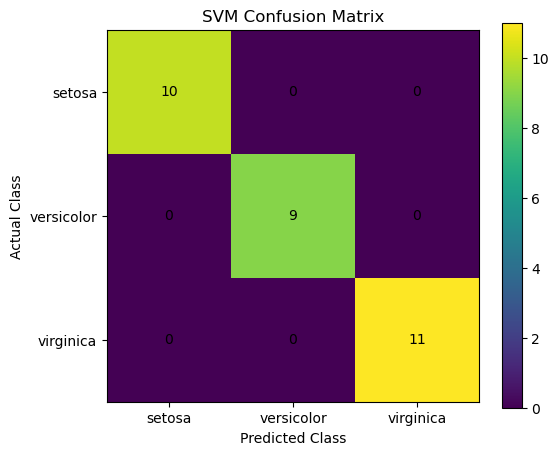

In [15]:
# Display the confusion matrix as a graph
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

# Display class names on the axes
plt.xticks(
    range(len(svm_model.classes_)),
    svm_model.classes_
)

plt.yticks(
    range(len(svm_model.classes_)),
    svm_model.classes_
)

# Display values inside the matrix
for i in range(len(cm)):
    for j in range(len(cm)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

In [16]:
# Create a new flower sample
sample = np.array([
    [5.1, 3.5, 1.4, 0.2]
])

# Scale the new sample using the same scaler
sample_scaled = scaler.transform(sample)

# Predict the class of the new flower
prediction = svm_model.predict(sample_scaled)

print("Prediction for new sample:", prediction[0])

Prediction for new sample: setosa


c:\Users\Acer\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [17]:
# Display the number of support vectors for each class
print("Support vectors for each class:")
print(svm_model.n_support_)

# Display total number of support vectors
print("\nTotal Support Vectors:")
print(len(svm_model.support_))

Support vectors for each class:
[ 8 20 18]

Total Support Vectors:
46


In [18]:
# Test different SVM kernels
kernels = ["linear", "poly", "rbf", "sigmoid"]

for kernel in kernels:

    # Create SVM model with selected kernel
    model = SVC(
        kernel=kernel,
        C=1.0,
        gamma="scale"
    )

    # Train the model
    model.fit(X_train_scaled, y_train)

    # Make predictions
    prediction = model.predict(X_test_scaled)

    # Calculate accuracy
    acc = accuracy_score(y_test, prediction)

    print(kernel, "Kernel Accuracy:", round(acc * 100, 2), "%")

linear Kernel Accuracy: 96.67 %
poly Kernel Accuracy: 96.67 %
rbf Kernel Accuracy: 100.0 %
sigmoid Kernel Accuracy: 90.0 %


In [19]:
# Test different values of C
C_values = [0.1, 1, 10, 100]

for c in C_values:

    # Create SVM model with different C value
    model = SVC(
        kernel="rbf",
        C=c,
        gamma="scale"
    )

    # Train the model
    model.fit(X_train_scaled, y_train)

    # Predict test data
    prediction = model.predict(X_test_scaled)

    # Calculate accuracy
    acc = accuracy_score(y_test, prediction)

    print("C =", c, 
          "Accuracy =", round(acc * 100, 2), "%")

C = 0.1 Accuracy = 96.67 %
C = 1 Accuracy = 100.0 %
C = 10 Accuracy = 96.67 %
C = 100 Accuracy = 100.0 %


In [20]:
# Display the final SVM results
print("========== FINAL RESULT ==========")

print("Algorithm : Support Vector Machine")
print("Kernel    : RBF")
print("C         : 1.0")
print("Gamma     : scale")

print("\nAccuracy :", round(accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

========== FINAL RESULT ==========
Algorithm : Support Vector Machine
Kernel    : RBF
C         : 1.0
Gamma     : scale

Accuracy : 100.0 %

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [21]:
# Display the conclusion of the practical
print("""
Conclusion:

SVM was successfully implemented using the Iris dataset.

The data was split into training and testing sets and
features were standardized using StandardScaler.

An SVM model with an RBF kernel was trained and used
to classify the flower species.

The model was evaluated using accuracy, confusion matrix,
precision, recall and F1-score.

Different kernels and C values were also tested to
understand their effect on SVM performance.
""")


Conclusion:

SVM was successfully implemented using the Iris dataset.

The data was split into training and testing sets and
features were standardized using StandardScaler.

An SVM model with an RBF kernel was trained and used
to classify the flower species.

The model was evaluated using accuracy, confusion matrix,
precision, recall and F1-score.

Different kernels and C values were also tested to
understand their effect on SVM performance.

